# Module 5 гэрийн даалгавар: CO₂ ялгарлыг эрчим хүчний хэрэглээгээр таамаглах

**Судалгааны асуулт:** Energy consumption-ийн өөрчлөлт CO₂ emissions-ийн өөрчлөлтийг ямар хэмжээнд тайлбарлаж чадах вэ?

**Улс:** Mongolia, 2000 оноос хойш  
**Dataset:** Our World in Data, CO₂ and Greenhouse Gas Emissions (https://github.com/owid/co2-data)

## Алхам 1. Dataset татах ба цэвэрлэх

In [1]:
import pandas as pd

url = "https://owid-public.owid.io/data/co2/owid-co2-data.csv"
# OWID server returns 403 for the default Python User-Agent, so a browser header is sent
df = pd.read_csv(url, storage_options={"User-Agent": "Mozilla/5.0"})

print(df.columns)
print(df.head())

Index(['country', 'year', 'iso_code', 'population', 'gdp', 'cement_co2',
       'cement_co2_per_capita', 'co2', 'co2_growth_abs', 'co2_growth_prct',
       'co2_including_luc', 'co2_including_luc_growth_abs',
       'co2_including_luc_growth_prct', 'co2_including_luc_per_capita',
       'co2_including_luc_per_gdp', 'co2_including_luc_per_unit_energy',
       'co2_per_capita', 'co2_per_gdp', 'co2_per_unit_energy', 'coal_co2',
       'coal_co2_per_capita', 'consumption_co2', 'consumption_co2_per_capita',
       'consumption_co2_per_gdp', 'cumulative_cement_co2', 'cumulative_co2',
       'cumulative_co2_including_luc', 'cumulative_coal_co2',
       'cumulative_flaring_co2', 'cumulative_gas_co2', 'cumulative_luc_co2',
       'cumulative_oil_co2', 'cumulative_other_co2', 'energy_per_capita',
       'energy_per_gdp', 'flaring_co2', 'flaring_co2_per_capita', 'gas_co2',
       'gas_co2_per_capita', 'ghg_excluding_lucf_per_capita', 'ghg_per_capita',
       'land_use_change_co2', 'land_use_chang

In [2]:
country = "Mongolia"
data = df[(df["country"] == country) & (df["year"] >= 2000)]

print("Rows before dropna:", len(data))
data = data[["year", "primary_energy_consumption", "co2"]].dropna()
print("Rows after dropna:", len(data))
print("Period:", data["year"].min(), "-", data["year"].max())
print(data.tail())

Rows before dropna: 25
Rows after dropna: 25
Period: 2000 - 2024
       year  primary_energy_consumption        co2
30558  2020                   62.500416  42.477501
30559  2021                   60.842049  35.971699
30560  2022                   52.860455  40.443169
30561  2023                   72.678558  44.183662
30562  2024                   76.833969  44.693890


Нэгж (OWID codebook): `primary_energy_consumption` нь TWh, `co2` нь сая тонн (million tonnes).

In [3]:
data.describe().round(2)

,year,primary_energy_consumption,co2
count,25.00,25.00,25.00
mean,2012.00,40.18,24.84
std,7.36,18.95,15.09
min,2000.00,16.86,7.43
25%,2006.00,21.48,9.28
50%,2012.00,41.81,23.28
75%,2018.00,52.86,40.44
max,2024.00,76.83,47.12


## Алхам 2. Regression model сургах

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

X = data[["primary_energy_consumption"]]
y = data["co2"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

r2 = r2_score(y_test, pred)
mae = mean_absolute_error(y_test, pred)

print("R² Score:", r2)
print("MAE:", mae)

R² Score: 0.9110983052949302
MAE: 2.739896539447581


In [5]:
print("Train size:", len(X_train), " Test size:", len(X_test))
print("Coefficient (Mt CO₂ per TWh):", model.coef_[0])
print("Intercept (Mt):", model.intercept_)

result = pd.DataFrame({
    "year": data.loc[X_test.index, "year"],
    "energy_TWh": X_test["primary_energy_consumption"],
    "actual_co2": y_test,
    "predicted_co2": pred,
}).sort_values("year")
result["error"] = result["predicted_co2"] - result["actual_co2"]
result.round(2)

Train size: 20  Test size: 5
Coefficient (Mt CO₂ per TWh): 0.7768876687090024
Intercept (Mt): -5.832873839208446


,year,energy_TWh,actual_co2,predicted_co2,error
30538,2000,16.99,7.43,7.37,-0.06
30546,2008,25.12,11.92,13.68,1.77
30549,2011,35.16,21.37,21.49,0.12
30554,2016,47.33,25.63,30.94,5.31
30561,2023,72.68,44.18,50.63,6.45


## Алхам 3. Үр дүнг дүрслэх

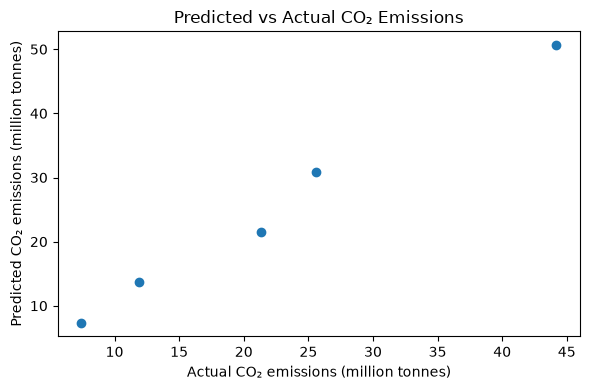

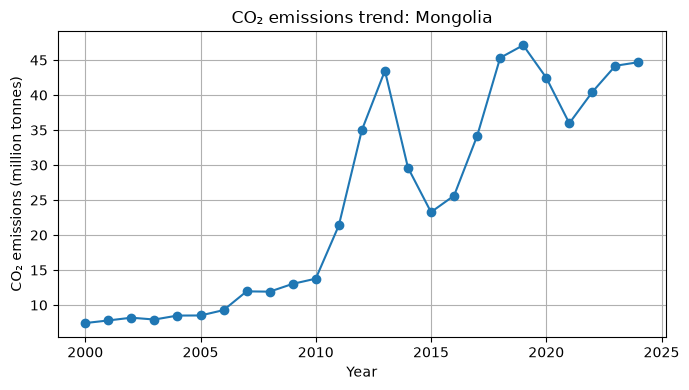

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.scatter(y_test, pred)
plt.xlabel("Actual CO₂ emissions (million tonnes)")
plt.ylabel("Predicted CO₂ emissions (million tonnes)")
plt.title("Predicted vs Actual CO₂ Emissions")
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

plt.figure(figsize=(7,4))
plt.plot(data["year"], data["co2"], marker="o")
plt.xlabel("Year")
plt.ylabel("CO₂ emissions (million tonnes)")
plt.title(f"CO₂ emissions trend: {country}")
plt.grid(True)
plt.tight_layout()
plt.savefig("co2_trend.png", dpi=150)
plt.show()